# R6 따라 하기: 대조군을 덜 읽으면 무엇이 달라지나 (재학습 없음)

이 노트북은 두 부분입니다.

1. **장난감 예시(가상 숫자)** 로 count 박화와 library size 계산을 손으로 확인합니다. 실제 세포 자료가 필요 없습니다.
2. 저장소에 커밋된 **작은 결과표(실제 수치)** 를 읽어 관측 진단 → 개발 fold 비교 → 동결 뒤 시험 약물 평가를 다시 봅니다.

필요한 것: numpy, pandas, matplotlib. GPU·서버·세포 배열은 필요 없습니다. 저장소 루트에서 실행하세요.

`jupyter nbconvert --to notebook --execute --inplace tutorials/depth_robust_r6/01_thinning_and_results.ipynb`

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parents[1]
T = ROOT / "reports/depth_robust_r6/tables"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print(sorted(p.name for p in T.iterdir()))

['dev_selected_by_line.tsv', 'dev_selected_inputs.json', 'dev_selected_main.tsv', 'dev_selected_pairs.tsv', 'dev_selected_snu423.tsv', 'final_by_line.tsv', 'final_inputs.json', 'final_main.tsv', 'final_pairs.tsv', 'final_snu423.tsv', 'pilot_curves.tsv', 'pilot_runs.tsv', 'r6_0_observation.json']


## 1. 장난감 예시 (가상 숫자): 한 세포를 25%만 읽기

세포 하나는 유전자별 UMI 개수입니다. "25%만 읽는다"는 것은 **분자 하나하나를 확률 0.25로 남기는 것**입니다(`Binomial(c, 0.25)`).
panel 밖 유전자의 합도 같은 방식으로 줄이고, library size는 **줄어든 값들의 합**으로 다시 계산합니다. 정규화 식은 항상 `log1p(1e4 · c / library)` 입니다.

In [2]:
rng = np.random.default_rng(0)
c = np.array([40, 12, 5, 2, 1, 1, 0, 0])      # 가상: panel 유전자 8개의 UMI
c_rest = 900                                   # 가상: panel 밖 유전자의 UMI 합
def view(c, c_rest, p, rng):
    if p == 1.0:
        return c.copy(), c_rest               # p=1은 아무것도 뽑지 않고 그대로
    return rng.binomial(c, p), int(rng.binomial(c_rest, p))
rows = []
for p in (1.0, 0.5, 0.25):
    cp, rp = view(c, c_rest, p, rng)
    lib = cp.sum() + rp                        # 박화된 합 = 새 library size
    rows.append(dict(p=p, counts=cp.tolist(), library=int(lib), detected=int((cp > 0).sum()),
                     lognorm=np.round(np.log1p(1e4 * cp / lib), 2).tolist()))
print(pd.DataFrame(rows).to_string(index=False))

   p                     counts  library  detected                                        lognorm
1.00 [40, 12, 5, 2, 1, 1, 0, 0]      961         6 [6.03, 4.84, 3.97, 3.08, 2.43, 2.43, 0.0, 0.0]
0.50  [21, 5, 1, 0, 1, 1, 0, 0]      483         5  [6.08, 4.65, 3.08, 0.0, 3.08, 3.08, 0.0, 0.0]
0.25  [10, 5, 2, 0, 1, 0, 0, 0]      233         4   [6.06, 5.37, 4.46, 0.0, 3.78, 0.0, 0.0, 0.0]


읽을 점: (i) 1개짜리 유전자는 자주 0이 됩니다(검출 유전자 수가 줄어듦). (ii) 남은 유전자의 정규화 값은 깊이가 얕아질수록 **들쭉날쭉**해집니다.
(iii) 그래서 세포 64개의 평균 프로필도 깊이에 따라 체계적으로 이동합니다. 아래 실제 수치에서 그 크기를 봅니다.

박화한 세포는 **같은 세포를 덜 읽은 것**입니다. 새 세포나 독립 반복이 아닙니다.

## 2. 실제 수치: 관측 진단 (R6-0)

In [3]:
o = json.loads((T / "r6_0_observation.json").read_text())
v = pd.DataFrame(o["views"])
keep = ["view", "median_library", "median_detected_panel_genes", "frac_cells_with_fewer_than_256_tokens",
        "setmean_shift_rms_in_between_pool_sd", "nearest_pool_correct_centred", "nearest_pool_correct_raw_euclid", "top256_token_overlap_with_full_mean"]
print(v[keep].round(3).to_string(index=False))
print("pools:", o["n_pools"], " truth delta RMS:", round(o["truth_delta_rms"], 4))

        view  median_library  median_detected_panel_genes  frac_cells_with_fewer_than_256_tokens  setmean_shift_rms_in_between_pool_sd  nearest_pool_correct_centred  nearest_pool_correct_raw_euclid  top256_token_overlap_with_full_mean
    p1.0_N64          1882.0                        490.0                                  0.038                                 0.000                           1.0                            1.000                                0.997
    p1.0_N16          1882.0                        490.0                                  0.038                                 0.724                           1.0                            1.000                                0.997
 p0.5_s2_N64           938.0                        293.0                                  0.390                                 0.634                           1.0                            0.996                                0.651
 p0.5_s1_N64           940.0                        293.0   

`setmean_shift…`는 "대조군 64개 평균 프로필이 전체 관측 대비 얼마나 움직였나"를 pool 사이 표준편차 단위로 잰 값입니다. p=0.25에서는 pool 사이 차이만큼 움직입니다.
그래도 평균 이동을 빼면(`centred`) 어느 pool인지는 100% 맞힙니다. 즉 **정보는 남아 있고, 척도가 이동**합니다.

## 3. 실제 수치: 개발 fold — head 수정 전후와 arm 비교

개발 fold는 train 약물 안의 79개입니다. 설정을 고르는 데 쓴 값이므로 일반화 추정치가 아닙니다.

In [4]:
r = pd.read_csv(T / "pilot_runs.tsv", sep="\t")
r = r[r.status == "ok"]
best = r.loc[r.groupby(["arm", "head", "drug_shrink"]).dev_p025.idxmin()]
print(best[["arm", "head", "drug_shrink", "lr", "dev_p1", "dev_p05", "dev_p025"]].sort_values(["head", "drug_shrink", "arm"]).round(4).to_string(index=False))

    arm     head  drug_shrink     lr  dev_p1  dev_p05  dev_p025
    B00 additive          1.0 0.0010  0.0819   0.0820    0.0821
    B00 additive         10.0 0.0030  0.0800   0.0801    0.0802
    B01 additive         10.0 0.0030  0.0795   0.0795    0.0795
    B10 additive         10.0 0.0010  0.0812   0.0812    0.0813
    B11 additive         10.0 0.0030  0.0796   0.0797    0.0797
    DEN additive         10.0 0.0010  0.0808   0.0809    0.0810
NOSTATE additive         10.0 0.0030  0.0941   0.0941    0.0941
 TEACH0 additive         10.0 0.0010  0.0799   0.0825    0.0905
 TEACH1 additive         10.0 0.0003  0.0816   0.0838    0.0906
    B00    joint          0.0 0.0003  0.0936   0.0936    0.0936
    B01    joint          0.0 0.0030  0.0908   0.0908    0.0908
    B10    joint          0.0 0.0003  0.0937   0.0937    0.0937
    B11    joint          0.0 0.0030  0.0910   0.0910    0.0909
    DEN    joint          0.0 0.0003  0.0936   0.0936    0.0936
NOSTATE    joint          0.0 0.0030  0.

`joint` = 처음 head, `additive` = 수정 1(상태 전용 항 + 눌러 둔 약물 특이 항). 수정 1은 모든 arm에 똑같이 적용한 기본 모델 변경입니다.

`TEACH0/TEACH1`은 박화 증강 없이 전체 관측만 본 모델입니다. p=0.25 입력에서만 크게 나빠집니다 → **증강이 깊이 문제를 거의 다 해결**합니다.

## 4. 실제 수치: 동결 뒤 시험 약물 70개

In [5]:
m = pd.read_csv(T / "final_main.tsv", sep="\t")
w = m.pivot(index="arm", columns="p", values="delta_rmse").loc[lambda d: d[0.25].sort_values().index]
print(w.round(4).to_string())
p = pd.read_csv(T / "final_pairs.tsv", sep="\t")
print(p[p.p.isin([0.25, 1.0])][["a", "b", "p", "diff", "lo", "hi", "rel", "better_by_rule", "worse_by_rule"]].round(5).to_string(index=False))

p           0.25    0.50    1.00
arm                             
B01       0.0833  0.0833  0.0833
B11       0.0835  0.0835  0.0835
B00       0.0838  0.0837  0.0837
DEN       0.0842  0.0841  0.0841
B10       0.0844  0.0843  0.0843
Z0        0.0870  0.0867  0.0870
linemean  0.0920  0.0920  0.0920
TEACH1    0.0928  0.0857  0.0839
TEACH0    0.0948  0.0860  0.0834
NOSTATE   0.0964  0.0964  0.0964
nochange  0.1041  0.1041  0.1041
chemCPA   0.2064  0.1424  0.1059
  a        b    p     diff       lo       hi      rel  better_by_rule  worse_by_rule
B11      B00 1.00 -0.00024 -0.00034 -0.00014 -0.00284           False          False
B11      B00 0.25 -0.00025 -0.00035 -0.00015 -0.00295           False          False
B11       Z0 1.00 -0.00352 -0.00414 -0.00288 -0.04047            True          False
B11       Z0 0.25 -0.00346 -0.00490 -0.00198 -0.03980            True          False
B11      DEN 1.00 -0.00064 -0.00082 -0.00045 -0.00761           False          False
B11      DEN 0.25 -0.00064 -

`better_by_rule`은 '구간이 0을 제외하고 상대 차이가 1% 이상'일 때만 True입니다. 구간은 약물 그룹 70개를 다시 뽑아 계산했습니다(세포·seed는 독립 표본이 아님).

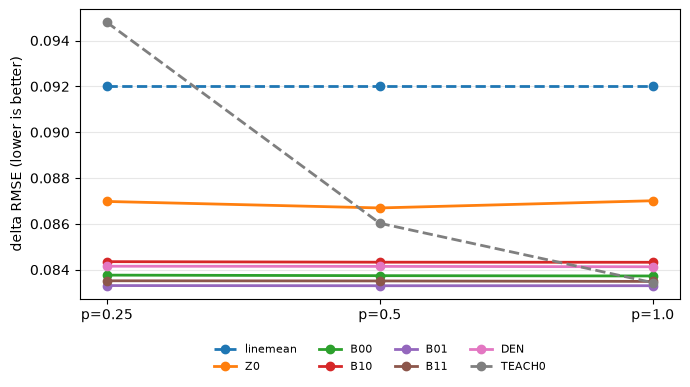

In [6]:
import matplotlib.pyplot as plt
order = [a for a in ["linemean", "Z0", "B00", "B10", "B01", "B11", "DEN", "TEACH0"] if a in w.index]
fig, ax = plt.subplots(figsize=(7, 4))
for a in order:
    ax.plot([0, 1, 2], w.loc[a, [0.25, 0.5, 1.0]], marker="o", lw=2, label=a, ls="--" if a in ("linemean", "TEACH0") else "-")
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["p=0.25", "p=0.5", "p=1.0"]); ax.set_ylabel("delta RMSE (lower is better)")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.grid(axis="y", alpha=.3)
fig.tight_layout(); plt.show()

## 5. SNU-423 (사전 지정한 HCC 하위 표)

세포주 하나의 결과입니다. 환자 HCC로 일반화하지 않습니다.

In [7]:
s = pd.read_csv(T / "final_snu423.tsv", sep="\t")
print(s[(s.kind == "arm") & s.p.isin([0.25, 1.0])][["a", "p", "value", "lo", "hi", "n_drugs"]].round(4).to_string(index=False))
print(s[(s.kind == "pair") & (s.p == 0.25)][["a", "b", "value", "lo", "hi"]].round(5).to_string(index=False))

       a    p  value     lo     hi  n_drugs
nochange 1.00 0.1121 0.1026 0.1236       70
nochange 0.25 0.1121 0.1026 0.1236       70
linemean 1.00 0.0989 0.0898 0.1098       70
linemean 0.25 0.0989 0.0898 0.1098       70
      Z0 1.00 0.0953 0.0864 0.1060       70
      Z0 0.25 0.0947 0.0859 0.1053       70
     B00 1.00 0.0921 0.0830 0.1031       70
     B00 0.25 0.0921 0.0831 0.1030       70
     B10 1.00 0.0926 0.0836 0.1035       70
     B10 0.25 0.0926 0.0836 0.1035       70
     B01 1.00 0.0915 0.0825 0.1025       70
     B01 0.25 0.0915 0.0824 0.1024       70
     B11 1.00 0.0919 0.0828 0.1028       70
     B11 0.25 0.0918 0.0827 0.1028       70
     DEN 1.00 0.0926 0.0836 0.1035       70
     DEN 0.25 0.0926 0.0836 0.1035       70
 NOSTATE 1.00 0.1022 0.0930 0.1134       70
 NOSTATE 0.25 0.1022 0.0930 0.1134       70
  TEACH0 1.00 0.0918 0.0828 0.1028       70
  TEACH0 0.25 0.1016 0.0919 0.1130       70
  TEACH1 1.00 0.0923 0.0832 0.1032       70
  TEACH1 0.25 0.1002 0.0904 0.11

## 정리

- 입력: 대조군 세포 64개의 (덜 읽은) UMI + 약물 구조. 정답: 실제로 측정한 처리 후 평균 변화(전체 관측, p와 무관).
- 무엇을 숨겼나: 시험 약물 70개의 처리군 전체. 세포주와 plate는 학습에서 본 것입니다.
- 결론과 한계는 `reports/depth_robust_r6/RESULTS.md`, `CLAIMS_AND_LIMITATIONS.md`를 보세요.